In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import osmnx as ox
import pandas as pd
import rasterio
from rasterio.plot import show

from rain2loss.gis import catchment_polygon
from rain2loss.loss import (JRC_BASE, JRC_RETURN_PERIODS, MAX_DAMAGE_CZ_TOTAL, average_annual_loss,
                            damage_ratio, download_jrc_window, download_window, loss_table,
                            sample_depth)
from rain2loss.paths import DATA_PROCESSED, RESULTS

GAUGE_ID = 824
catchment = catchment_polygon(GAUGE_ID)                 # EPSG:4326, like the JRC maps
JRC_DIR = DATA_PROCESSED / "jrc"
JRC_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
bounds = catchment.total_bounds
for rp in JRC_RETURN_PERIODS:
    out = JRC_DIR / f"jrc_rp{rp}_{GAUGE_ID}.tif"
    if not out.exists():
        download_jrc_window(rp, bounds, out)
spurious_file = JRC_DIR / f"jrc_spurious_{GAUGE_ID}.tif"
if not spurious_file.exists():
    download_window(JRC_BASE + "Europe_spurious_depth_areas.tif", bounds, spurious_file)
print(sorted(p.name for p in JRC_DIR.glob("*.tif")))

['jrc_rp100_824.tif', 'jrc_rp10_824.tif', 'jrc_rp200_824.tif', 'jrc_rp20_824.tif', 'jrc_rp30_824.tif', 'jrc_rp40_824.tif', 'jrc_rp500_824.tif', 'jrc_rp50_824.tif', 'jrc_rp75_824.tif', 'jrc_spurious_824.tif']


In [3]:
with rasterio.open(JRC_DIR / f"jrc_rp500_{GAUGE_ID}.tif") as src:
    depth500 = src.read(1, masked=True)
    rows, cols = np.nonzero(depth500.filled(0) > 0)
    xs, ys = rasterio.transform.xy(src.transform, rows, cols)
aoi = (min(xs) - 0.01, min(ys) - 0.01, max(xs) + 0.01, max(ys) + 0.01)   # flood zone + ~1 km
print("area of interest (lon/lat):", np.round(aoi, 3))

area of interest (lon/lat): [16.891 50.021 16.944 50.098]


In [5]:
ox.settings.use_cache = True
ox.settings.cache_folder = str(DATA_PROCESSED / "osm_cache")
raw = ox.features_from_bbox(aoi, tags={"building": True})
print(len(raw), "OSM features")

NOT_HOUSES = ["garage", "garages", "shed", "carport", "hut", "roof", "ruins",
              "construction", "greenhouse", "service", "transformer_tower"]
buildings = raw[raw.geometry.geom_type.isin(["Polygon", "MultiPolygon"])].reset_index()
buildings = buildings[~buildings["building"].isin(NOT_HOUSES)]
buildings = buildings[buildings.intersects(catchment.geometry.iloc[0])]
buildings = buildings[["id", "building", "geometry"]].copy()
buildings["footprint_m2"] = buildings.to_crs(3035).area
buildings["value_eur"] = buildings["footprint_m2"] * MAX_DAMAGE_CZ_TOTAL
print(len(buildings), "buildings, total value %.1f million EUR" % (buildings["value_eur"].sum() / 1e6))
buildings.to_file(DATA_PROCESSED / f"buildings_{GAUGE_ID}.gpkg")

1408 OSM features
768 buildings, total value 80.3 million EUR


In [6]:
points = buildings.copy()
points["geometry"] = buildings.to_crs(3035).representative_point().to_crs(4326)
depth_by_rp = {rp: sample_depth(JRC_DIR / f"jrc_rp{rp}_{GAUGE_ID}.tif", points)
               for rp in JRC_RETURN_PERIODS}
table = loss_table(points, depth_by_rp)
table["loss_million_eur"] = table["loss_eur"] / 1e6
table.to_csv(RESULTS / f"loss_by_return_period_{GAUGE_ID}.csv", index=False)
table.drop(columns="loss_eur").round(3)

,rp,aep,flooded_buildings,mean_depth_m,loss_million_eur
0,10,0.100,178,1.009,5.491
1,20,0.050,178,1.084,5.869
2,30,0.033,179,1.118,6.067
3,40,0.025,179,1.144,6.194
4,50,0.020,179,1.165,6.293
5,75,0.013,184,1.171,6.486
6,100,0.010,184,1.194,6.599
7,200,0.005,188,1.224,6.903
8,500,0.002,193,1.258,7.232


AAL: 599,594 EUR (0.75 % of the portfolio value)
AAL with defences up to RP20: 266,693 EUR


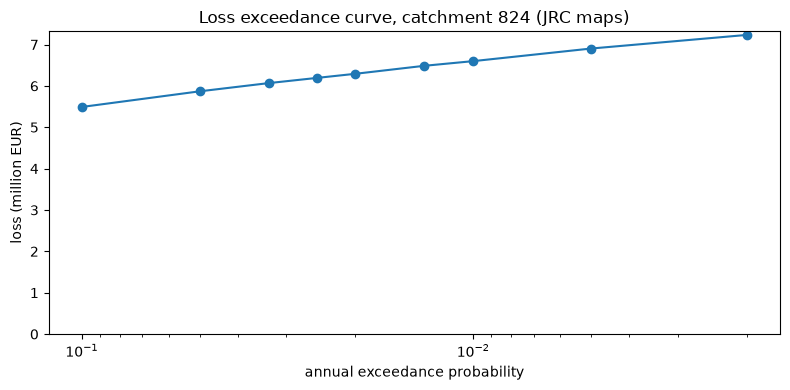

In [7]:
aal = average_annual_loss(table["rp"], table["loss_eur"])
aal_protected = average_annual_loss(table["rp"], table["loss_eur"], protection_rp=20)
print(f"AAL: {aal:,.0f} EUR ({100 * aal / buildings['value_eur'].sum():.2f} % of the portfolio value)")
print(f"AAL with defences up to RP20: {aal_protected:,.0f} EUR")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(table["aep"], table["loss_million_eur"], "o-")
ax.set_xscale("log")
ax.invert_xaxis()
ax.set_ylim(bottom=0)
ax.set(xlabel="annual exceedance probability", ylabel="loss (million EUR)",
       title="Loss exceedance curve, catchment 824 (JRC maps)")
plt.tight_layout()
plt.show()

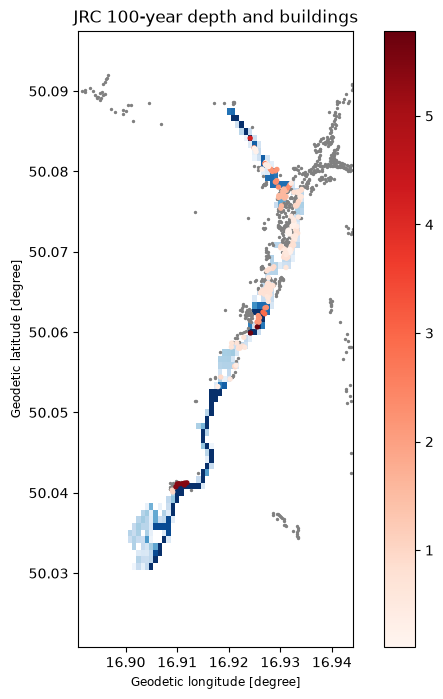

In [8]:
fig, ax = plt.subplots(figsize=(8, 8))
with rasterio.open(JRC_DIR / f"jrc_rp100_{GAUGE_ID}.tif") as src:
    show(src.read(1, masked=True), transform=src.transform, ax=ax, cmap="Blues", vmin=0, vmax=3)
points["depth_rp100"] = depth_by_rp[100]
points[points["depth_rp100"] == 0].plot(ax=ax, color="grey", markersize=2)
points[points["depth_rp100"] > 0].plot(ax=ax, column="depth_rp100", cmap="Reds", markersize=8, legend=True)
ax.set(xlim=(aoi[0], aoi[2]), ylim=(aoi[1], aoi[3]), title="JRC 100-year depth and buildings")
plt.show()

In [9]:
flagged = sample_depth(spurious_file, points) > 0
wet = points["depth_rp100"] > 0
loss100 = points["value_eur"] * damage_ratio(points["depth_rp100"])
print(f"{int((wet & flagged).sum())} of {int(wet.sum())} flooded buildings are in JRC 'spurious depth' areas")
print(f"their share of the 100-year loss: {100 * loss100[flagged].sum() / loss100.sum():.0f} %")
print(f"mean depth: flagged {points.loc[wet & flagged, 'depth_rp100'].mean():.2f} m, "
      f"others {points.loc[wet & ~flagged, 'depth_rp100'].mean():.2f} m")

26 of 184 flooded buildings are in JRC 'spurious depth' areas
their share of the 100-year loss: 24 %
mean depth: flagged 2.19 m, others 1.03 m


In [10]:
with rasterio.open(DATA_PROCESSED / "hand_3035.tif") as src:
    xy = points.to_crs(src.crs)
    hand = np.array([v[0] for v in src.sample(zip(xy.geometry.x, xy.geometry.y))], dtype=float)
points["hand_m"] = hand
low = points["hand_m"] < 3
pd.crosstab(low.rename("HAND < 3 m"), wet.rename("JRC RP100 wet"))

JRC RP100 wet,False,True
HAND < 3 m,,
False,395,22
True,189,162
